# 3. 멀티모달 RAG

PDF 분할 작업을 위해 `unstructured`를 사용합니다. `unstructured` 를 위해 다음과 도구의 설치가 필요합니다:

- `tesseract` : 광학 문자 인식(OCR)을 위해 사용
- `poppler` : PDF 렌더링 및 처리

[poppler 설치 방법](https://pdf2image.readthedocs.io/en/latest/installation.html)과 [tesseract 설치 방법](https://tesseract-ocr.github.io/tessdoc/Installation.html)을 참고하여 설치해주세요.

In [1]:
%%capture --no-stderr
!sudo apt install tesseract-ocr
!sudo apt install libtesseract-dev
!sudo apt-get install poppler-utils

In [2]:
%%capture --no-stderr
! pip install -U langchain openai chromadb langchain-experimental langchain_openai nltk pydantic lxml matplotlib chromadb tiktoken
! pip install pillow == 11.1.0
! pip install "unstructured[all-docs]" == 0.17.2

In [2]:
from dotenv import load_dotenv

# .env 파일에서 환경 변수 로드
load_dotenv("../.env")

True

In [3]:
import nltk

nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Administrator\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\Administrator\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


True

In [13]:
# 파일 경로
fpath = 'cropped_pdf/'
fname = "sample.pdf"

In [ ]:
from unstructured.partition.pdf import partition_pdf
import os

# PDF에서 요소 추출
raw_pdf_elements = partition_pdf(
    filename=fname,
    extract_images_in_pdf=True,
    extract_image_block_types=["Image", "Table"],
    chunking_strategy="by_title",
    extract_image_block_output_dir=fpath,
)

Thank you for using Unstructured Open Source! Try Unstructured's commercial offering for improved output quality. 10,000 free pages to start. Learn more: https://transform.unstructured.io/?utm_source=unstructured_oss Hide this notice: UNSTRUCTURED_DISABLE_NOTICE=1
No languages specified, defaulting to English.


In [6]:
# 텍스트, 테이블 추출
tables = []
texts = []
for element in raw_pdf_elements:
    if "unstructured.documents.elements.Table" in str(type(element)):
        tables.append(str(element))  # 테이블 요소 추가
    elif "unstructured.documents.elements.CompositeElement" in str(type(element)):
        texts.append(str(element))  # 텍스트 요소 추가

In [7]:
tables[0]

'2020년 2023년 2024년 42주 2022년 2021년 294 420 747 665 전체 385 국내발생 356 630 673 382 274 20 38 29 해외유입 74 35'

In [9]:
print(texts[0])

42주차 (10.13.~10.19.)

2 e FR | May | Suey | aieicel

주차

국내발생 해외유입

전체


In [ ]:
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI

# 프롬프트 설정
prompt_text = """당신은 표와 텍스트를 요약하여 검색할 수 있도록 돕는 역할을 맡은 어시스턴트입니다.
이 요약은 임베딩되어 원본 텍스트나 표 요소를 검색하는 데 사용될 것입니다.
표 또는 텍스트에 대한 간결한 요약을 제공하여 검색에 최적화된 형태로 만들어 주세요. 표 또는 텍스트: {element} """
prompt = ChatPromptTemplate.from_template(prompt_text)

# 텍스트 요약 체인
model = ChatOpenAI(temperature=0, model="gpt-4o")
summarize_chain = {"element": lambda x: x} | prompt | model | StrOutputParser()

# 제공된 텍스트에 대해 요약을 할 경우
text_summaries = summarize_chain.batch(texts, {"max_concurrency": 5})
# 요약을 원치 않을 경우
# text_summaries = texts

# 제공된 테이블에 적용
table_summaries = summarize_chain.batch(tables, {"max_concurrency": 5})

In [11]:
print(table_summaries[0])

**요약:**  
- **연도별 발생 현황:**  
  - **2020년:** 전체 294, 국내 274, 해외 20  
  - **2021년:** 전체 420, 국내 382, 해외 38  
  - **2022년:** 전체 747, 국내 630, 해외 35  
  - **2023년:** 전체 665, 국내 673, 해외 29  
  - **2024년:** 42주 기준 데이터 없음  

**전체 발생:** 385 (2020년)  
**국내 발생:** 356 (2020년)  
**해외 유입:** 74 (2020년)  

이 데이터는 연도별 전체, 국내, 해외 발생 수치를 포함하고 있습니다.


In [12]:
print(text_summaries[0])

42주차 (10.13.~10.19.) 국내 발생 및 해외 유입 데이터 요약: 전체 발생 수 포함.


In [14]:
import base64


def encode_image(image_path) -> str:
    # 이미지 base64 인코딩
    with open(image_path, "rb") as image_file:
        return base64.b64encode(image_file.read()).decode('utf-8')


# 이미지의 base64 인코딩을 저장하는 리스트
img_base64_list = []

# 이미지를 읽어 base64 인코딩 후 저장
for img_file in sorted(os.listdir(fpath)):
    if img_file.endswith('.jpg'):
        img_path = os.path.join(fpath, img_file)
        base64_image = encode_image(img_path)
        img_base64_list.append(base64_image)

In [15]:
len(img_base64_list)

51

In [16]:
from langchain_core.messages import HumanMessage
from langchain_openai import ChatOpenAI


def image_summarize(img_base64: str) -> str:
    # 이미지 요약
    chat = ChatOpenAI(model="gpt-4o")
    prompt = """
    당신은 이미지를 요약하여 검색을 위해 사용할 수 있도록 돕는 어시스턴트입니다.
    이 요약은 임베딩되어 원본 이미지를 검색하는 데 사용됩니다.
    이미지 검색에 최적화된 간결한 요약을 작성하세요.
    """
    msg = chat.invoke(
        [
            HumanMessage(
                content=[
                    {"type": "text", "text": prompt},
                    {
                        "type": "image_url",
                        "image_url": {
                            "url": f"data:image/jpeg;base64,{img_base64}"
                        },
                    },
                ]
            )
        ]
    )
    return msg.content #type: ignore


# 이미지 요약을 저장하는 리스트
image_summaries = []

for img_base64 in img_base64_list:
    image_summary = image_summarize(img_base64)
    image_summaries.append(image_summary)


In [17]:
image_summaries[0]

'질병관리청 2024년 말라리아 주간 소식지 표지, 42주차 (10.13~10.19).'

In [19]:
print(image_summaries[21])

남녀 연령대별 발생 수; 20-29세 남성에서 가장 높은 발생, 그 외 연령대는 남성이 더 많음; 연령대: 0-9세부터 70세 이상.


In [20]:
from langchain_classic.retrievers import MultiVectorRetriever
from langchain_core.stores import InMemoryStore
from langchain_openai import OpenAIEmbeddings
from langchain_community.vectorstores import Chroma

# 분할한 텍스트들을 색인할 벡터 저장소
vectorstore = Chroma(collection_name="multi_modal_rag",
                     embedding_function=OpenAIEmbeddings())

# 원본문서 저장을 위한 저장소 선언
docstore = InMemoryStore()
id_key = "doc_id"

# 검색기
retriever = MultiVectorRetriever(
    vectorstore=vectorstore,
    docstore=docstore,
    id_key=id_key,
)

C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_12596\2488022287.py:4: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import Chroma
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_12596\2488022287.py:7: LangChainDeprecationWarning: The class `Chroma` was deprecated in LangChain 0.2.9 and will be removed in 1.0. An updated version of the class exists in the `langchain-chroma package and should be used instead. To use it run `pip install -U `langchain-chroma` and import as `from `langchain_chroma import Chroma``.
  vectorstore = Chroma(collection_name="multi_modal_rag",


In [21]:
import uuid

# 원본 텍스트 데이터 저장
doc_ids = [str(uuid.uuid4()) for _ in texts]
retriever.docstore.mset(list(zip(doc_ids, texts)))

# 원본 테이블 데이터 저장
table_ids = [str(uuid.uuid4()) for _ in tables]
retriever.docstore.mset(list(zip(table_ids, tables)))

# 원본 이미지(base64) 데이터 저장
img_ids = [str(uuid.uuid4()) for _ in img_base64_list]
retriever.docstore.mset(list(zip(img_ids, img_base64_list)))

In [ ]:
from langchain_core.documents import Document

# 텍스트 요약 벡터 저장
summary_texts = [Document(page_content=s, metadata={id_key: doc_ids[i]}) for i, s in enumerate(text_summaries)]
retriever.vectorstore.add_documents(summary_texts)

# 테이블 요약 벡터 저장
summary_tables = [Document(page_content=s, metadata={id_key: table_ids[i]}) for i, s in enumerate(table_summaries)]
retriever.vectorstore.add_documents(summary_tables)

# 이미지 요약 벡터 저장

summary_img = [Document(page_content=s, metadata={id_key: img_ids[i]}) for i, s in enumerate(image_summaries)]
retriever.vectorstore.add_documents(summary_img)

['a74ed9a2-4b65-4af7-8808-f6fa75f98c26',
 '22c1d3d2-77bf-464c-bc36-51068a4b968e',
 '64cbacce-45fa-4cd4-b08f-901650aeb3a3',
 '86852617-5b4f-40ec-9ae1-1587b7a27b7b',
 '7b2fb672-f420-47eb-89f0-5b5cde768576',
 'e3a863ba-3fe9-476e-b206-b41045f4f90c',
 '35bf2ad0-f3a4-43f8-a207-753f80da08c6',
 'ce6908eb-3295-415f-a0d9-75ea0ddc1bea',
 'cf885de2-59ae-4cc3-9d79-d89c7ab30345',
 '84afc6ee-335a-4c24-b735-bffbab8cda0d',
 '946c6161-17c6-4986-a3ba-227448525613',
 '9b98cbd0-ec5e-4752-94f0-64b830dbc26c',
 'a8e8ff3f-2ee7-4143-8cc2-b9f77d219e97',
 'ff432e9d-3ccb-4110-b2c2-d25fb4c12d8a',
 'f1ffb723-4694-458b-8f50-112403352a6a',
 'd8b63fd9-d7ed-4323-8f96-dbc4cdda63fb',
 'ddeb2a38-c088-4960-8404-c6f823195398',
 'e8bc6cc8-3f19-4e25-91be-9bf84fef2b4a',
 '079d7bcd-4919-4387-aefb-79fdf05b6ff4',
 'b08935a2-150d-43b8-882c-35e08cd9c8a2',
 'ab136909-01d2-4e37-905c-30ac8e76dd64',
 '4ba08e95-e11f-426f-8aac-3b4075eec6ca',
 '82955a13-f034-4090-9604-1b663cd284fc',
 '4cbb7429-007e-4cfd-a062-32d13cf656e2',
 '54cdb134-db99-

In [23]:
docs = retriever.invoke(
    "말라리아 군집 사례는 어떤가요? "
)

In [24]:
len(docs)

4

In [25]:
from base64 import b64decode

def split_image_text_types(docs):
    # 이미지와 텍스트 데이터를 분리
    b64 = []
    text = []
    for doc in docs:
        try:
            b64decode(doc)
            b64.append(doc)
        except Exception as e:
            text.append(doc)
    return {
        "images": b64,
        "texts": text
    }

docs_by_type = split_image_text_types(docs)

In [26]:
len(docs_by_type["images"])

2

In [27]:
len(docs_by_type["texts"])

2

In [28]:
docs_by_type["images"][0][:100]

'/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAx'

In [29]:
docs_by_type["texts"]

['42주차 (10.13.~10.19.) 3 말라리아 군집사례 현황 - (누적) 4개 시도(경기, 서울, 인천, 강원), 총 46건의 군집사례* 확인 * 군집사례 : 위험지역 내에서 2명 이상의 환자가 증상 발생 간격이 14일 이내, 환자 거주지 거리가 1Km 이내인 경우 표6 군집사례 발생 현황 사례건수(환자수) 시·도 시군구 발생(군집사례건수) 4개 시도 46건(114명) 합계 ▸5명 군집(1) : 양천구, 강서구(1) 1건(5명) 서울 ▸2명 군집(5) : 서구(2), 강화군(1), 연수구(1), 중구(1) 인천 5건(10명) ▸6명 군집(1) : 파주시(1) ▸4명 군집(3) : 파주시(2), 김포시(1), ▸3명 군집(6) : 파주시(4), 김포시(1), 일산서구(1) 경기 39건(94명) ▸2명 군집(29) : 파주시(15), 김포시(10), 일산동구(2), 일산서구(1), 연천군(1) ▸5명 군집(1) : 철원군(1) 1건(5명) 강원 그림 6. 군집사례 6',
 '42주차 (10.13.~10.19.)\n\n3 말라리아 군집사례 현황\n\n* 군집사례 : 위험지역 내에서 2명 이상의 환자가 증상 발생 간격이 14일 이내, 환자 거주지 거리가 1Km 이내인 경우\n\n그림 6. 군집사례\n\n6']


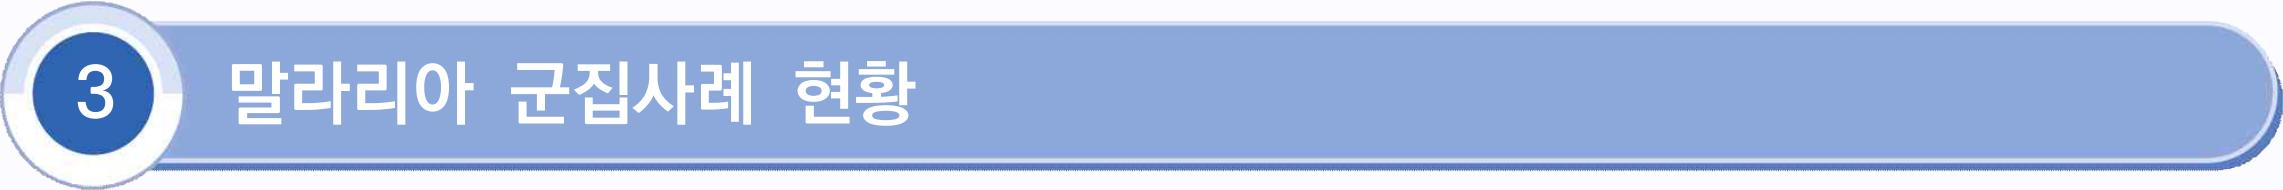

In [30]:

from IPython.display import display, HTML

def plt_img_base64(img_base64):
    # base64 이미지로 html 태그를 작성합니다
    image_html = f'<img src="data:image/jpeg;base64,{img_base64}" />'

    # html 태그를 기반으로 이미지를 표기합니다
    display(HTML(image_html))

plt_img_base64(docs_by_type["images"][0])

In [31]:
print(docs_by_type["texts"][0])

42주차 (10.13.~10.19.) 3 말라리아 군집사례 현황 - (누적) 4개 시도(경기, 서울, 인천, 강원), 총 46건의 군집사례* 확인 * 군집사례 : 위험지역 내에서 2명 이상의 환자가 증상 발생 간격이 14일 이내, 환자 거주지 거리가 1Km 이내인 경우 표6 군집사례 발생 현황 사례건수(환자수) 시·도 시군구 발생(군집사례건수) 4개 시도 46건(114명) 합계 ▸5명 군집(1) : 양천구, 강서구(1) 1건(5명) 서울 ▸2명 군집(5) : 서구(2), 강화군(1), 연수구(1), 중구(1) 인천 5건(10명) ▸6명 군집(1) : 파주시(1) ▸4명 군집(3) : 파주시(2), 김포시(1), ▸3명 군집(6) : 파주시(4), 김포시(1), 일산서구(1) 경기 39건(94명) ▸2명 군집(29) : 파주시(15), 김포시(10), 일산동구(2), 일산서구(1), 연천군(1) ▸5명 군집(1) : 철원군(1) 1건(5명) 강원 그림 6. 군집사례 6



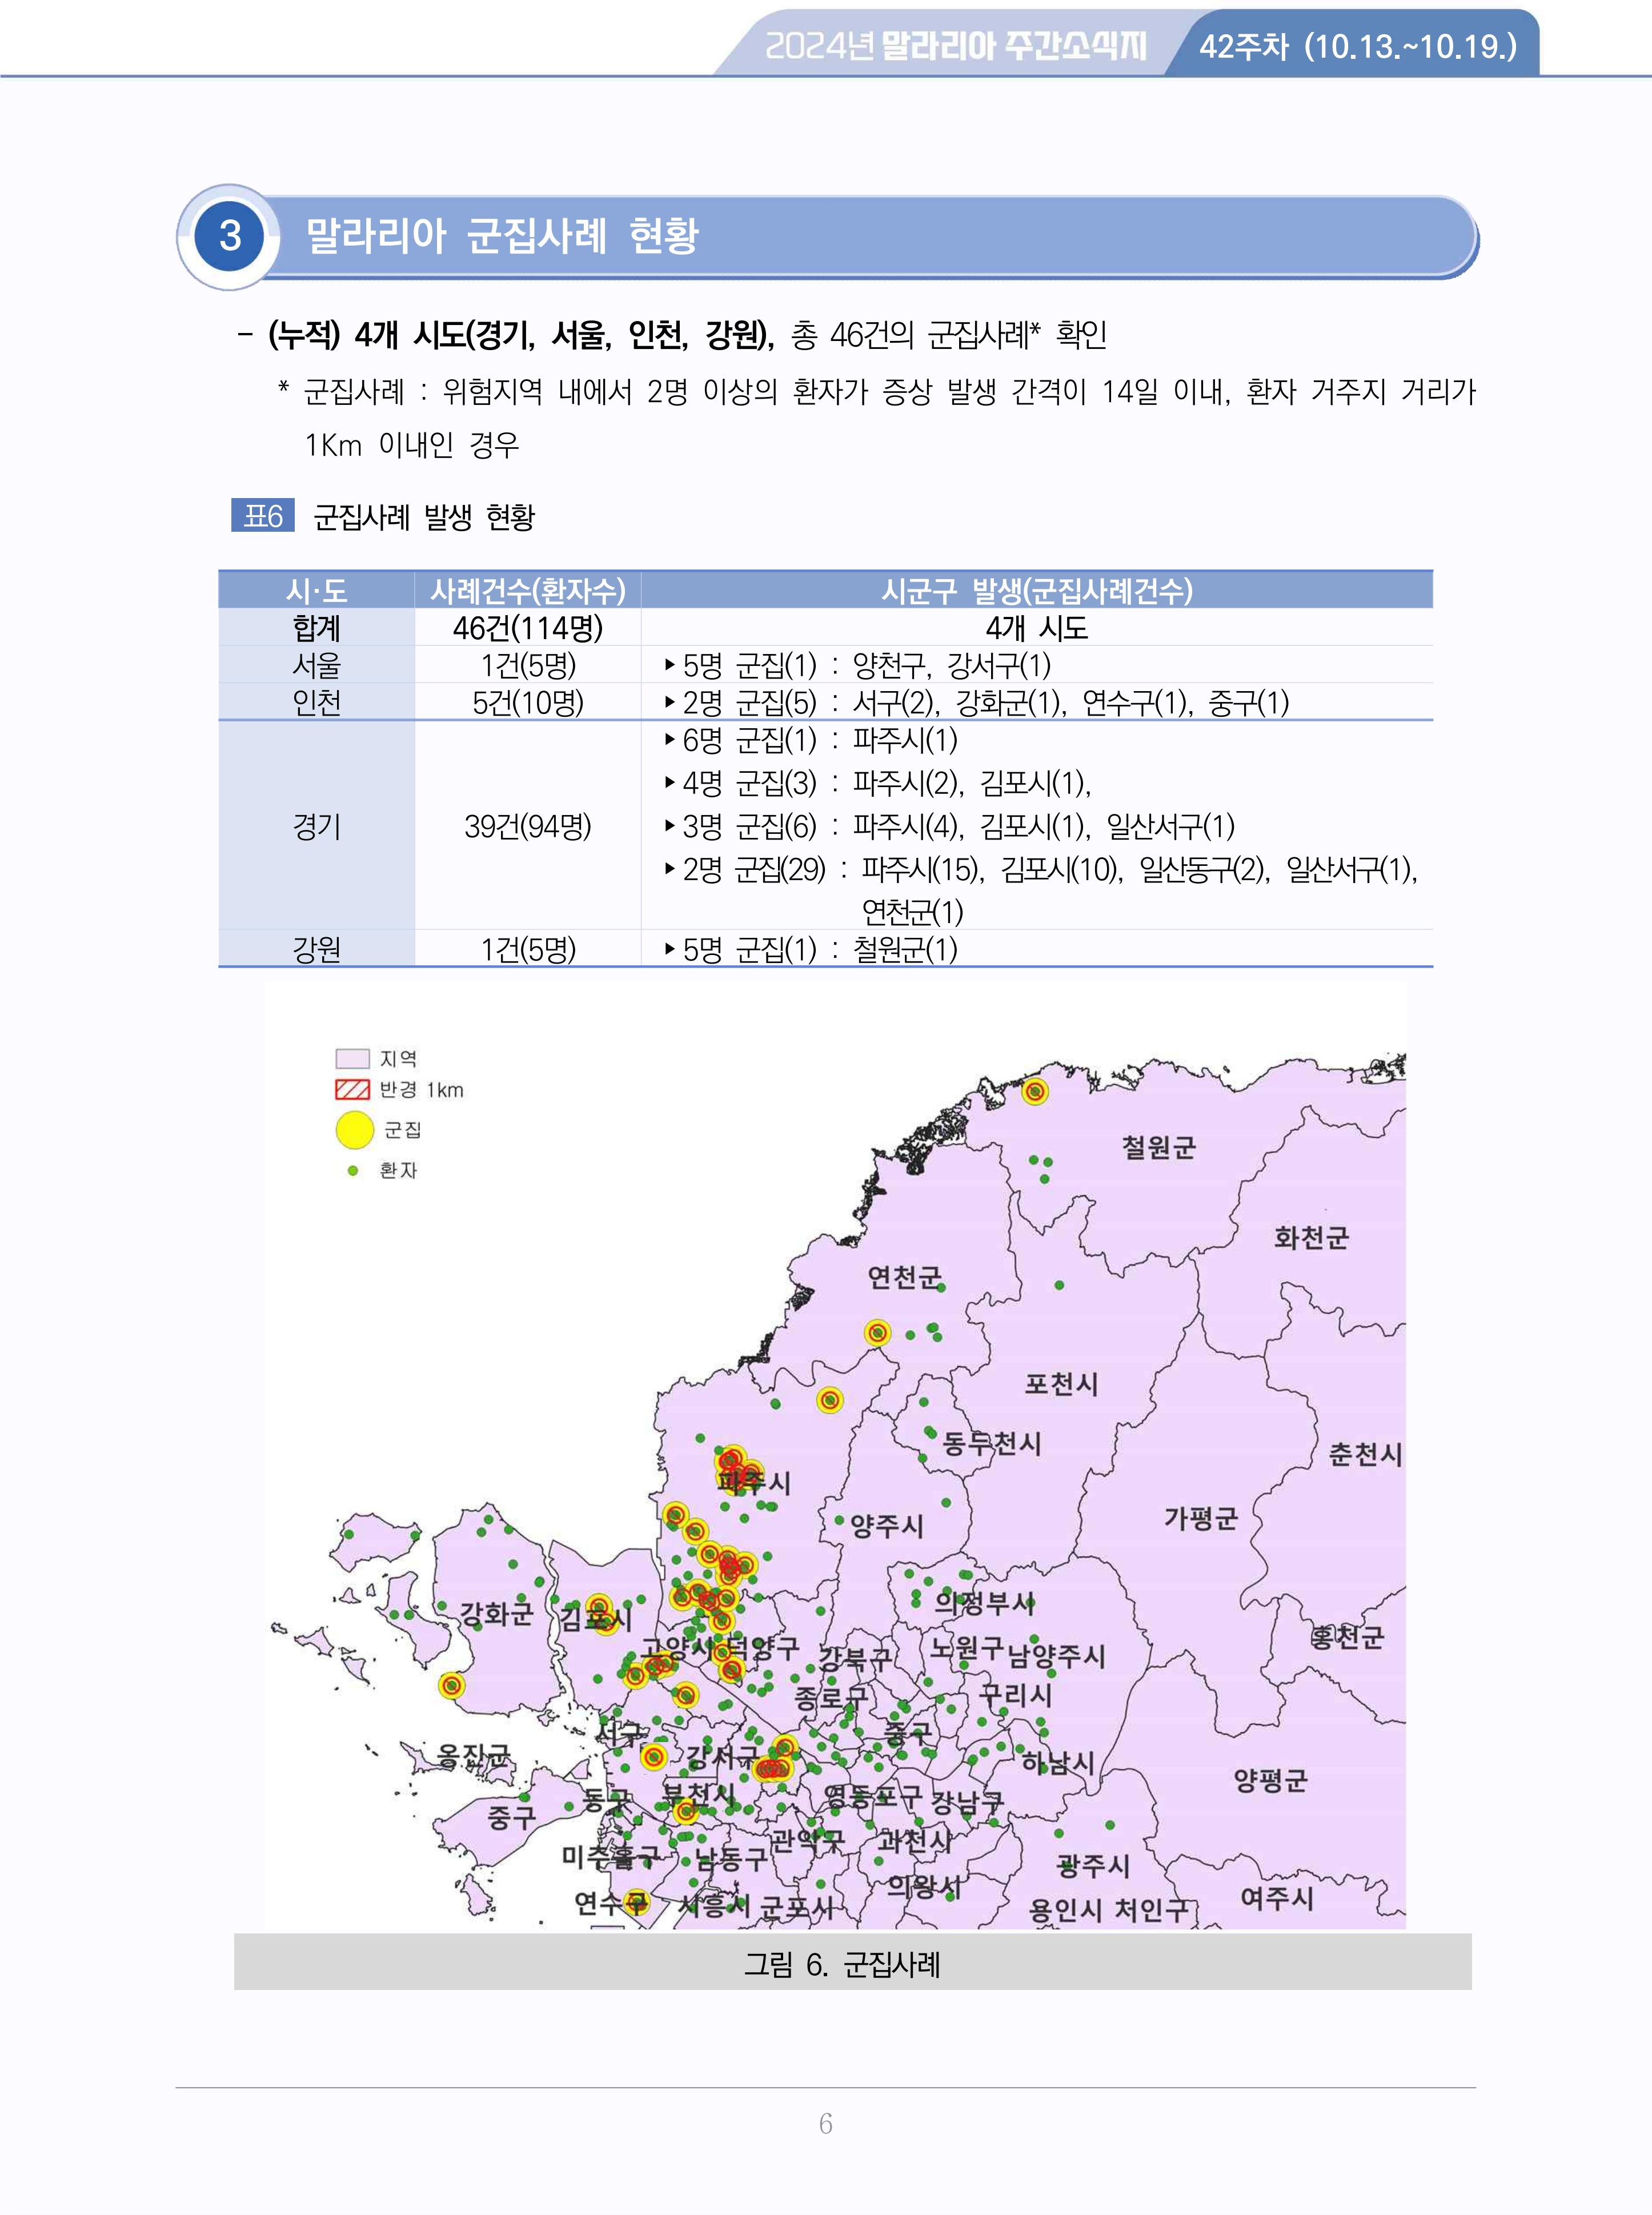

In [32]:
plt_img_base64(docs_by_type["images"][1])

In [33]:
print(docs_by_type["texts"][1])

42주차 (10.13.~10.19.)

3 말라리아 군집사례 현황

* 군집사례 : 위험지역 내에서 2명 이상의 환자가 증상 발생 간격이 14일 이내, 환자 거주지 거리가 1Km 이내인 경우

그림 6. 군집사례

6


In [34]:
#from operator import itemgetter
from langchain_core.runnables import RunnablePassthrough, RunnableLambda

def prompt_func(dict):
    format_texts = "\n".join(dict["context"]["texts"])
    text = f"""
    다음 문맥에만 기반하여 질문에 답하세요. 문맥에는 텍스트, 표, 그리고 아래 이미지가 포함될 수 있습니다:
    질문: {dict["question"]}

    텍스트와 표:
    {format_texts}
    """

    prompt = [
        HumanMessage(
            content=[
                {"type": "text", "text": text},
                {"type": "image_url", "image_url": {"url": f"data:image/jpeg;base64,{dict['context']['images'][0]}"}},
            ]
        )
    ]

    return prompt


model = ChatOpenAI(temperature=0, model="gpt-4o")

# RAG 파이프라인
chain = (
        {"context": retriever | RunnableLambda(split_image_text_types), "question": RunnablePassthrough()}
        | RunnableLambda(prompt_func)
        | model
        | StrOutputParser()
)

In [35]:
chain.invoke(
    "말라리아 군집 사례는 어떤가요?"
)

'42주차(10.13.~10.19.) 동안 말라리아 군집 사례는 총 4개 시도(경기, 서울, 인천, 강원)에서 46건이 확인되었습니다. 군집 사례는 위험 지역 내에서 2명 이상의 환자가 증상 발생 간격이 14일 이내이고, 환자 거주지 거리가 1Km 이내인 경우를 말합니다. \n\n- 서울에서는 1건(5명)이 발생했습니다.\n- 인천에서는 5건(10명)이 발생했습니다.\n- 경기에서는 39건(94명)이 발생했습니다.\n- 강원에서는 1건(5명)이 발생했습니다.'

In [36]:
chain.invoke(
    "말라리아 증상을 설명해주세요"
)

'말라리아 증상은 48시간을 주기로 반복되며, 초기에는 오한, 발열, 발한이 나타납니다. 또한 두통, 설사, 구토 등의 증상이 동반될 수 있습니다. 추가로 피로, 오심, 근육통도 나타날 수 있습니다.'

In [38]:
chain.invoke(
    "말라리아 매개모기 채집 지점은 어디인가요?"
)

'말라리아 매개모기 채집 지점은 인천, 경기, 강원 북부, 서울 지역입니다.'